
# Lab Assignment 8: NLP using Python-II  
**Student Name:** Prerna Garg  
**Roll Number:** 1024160066


>

In [14]:


import re
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
import nltk

for resource in [
    "punkt", "punkt_tab", "stopwords", "wordnet",
    "omw-1.4", "vader_lexicon"
]:
    nltk.download(resource, quiet=True)

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from textblob import TextBlob
from wordcloud import WordCloud

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.utils import to_categorical



---
## Question 1 — Cleaning, Tokenization, Stopwords & Frequency


In [18]:
paragraph = """
World War I was a major global conflict that lasted from 1914 to 1918, involving many of the world's powerful nations and causing profound political, social, and economic changes across Europe and beyond. The war began following the assassination of Archduke Franz Ferdinand of Austria-Hungary in Sarajevo in June 1914, triggering a series of diplomatic crises and military mobilizations among competing alliances.

The conflict was primarily fought between the Allied Powers, including Britain, France, Russia, and later the United States, and the Central Powers, consisting mainly of Germany, Austria-Hungary, the Ottoman Empire, and Bulgaria. These nations mobilized millions of soldiers and resources, transforming the war into an industrial-scale conflict characterized by modern weapons, extensive artillery bombardments, machine guns, chemical warfare, and the first widespread military use of aircraft and tanks.

Trench warfare became a defining feature of the Western Front, where soldiers endured harsh living conditions, persistent artillery fire, disease, and prolonged stalemates. Battles such as Verdun, the Somme, and Passchendaele resulted in enormous casualties while producing limited territorial gains. Meanwhile, the Eastern Front, the Middle East, Africa, and the seas witnessed additional military campaigns that expanded the geographical scope of the conflict.

The war had far-reaching consequences for civilian populations, as governments introduced rationing, expanded industrial production, and mobilized entire societies to support military operations. Women entered factories, transportation services, and other occupations in greater numbers, while shortages, displacement, and economic hardship affected millions of families. Propaganda and censorship also became important tools used by governments to maintain public support and encourage participation in the war effort.

World War I ended with the armistice of November 11, 1918, following the collapse of several Central Powers and growing political instability. The Treaty of Versailles, signed in 1919, imposed significant conditions on Germany, while the collapse of the German, Austro-Hungarian, Ottoman, and Russian empires reshaped international borders. The conflict contributed to revolutionary movements, the establishment of new states, and political tensions that influenced international relations and helped create conditions leading to World War II.
""".strip()

cleaned_text = re.sub(r"[^a-z0-9\s]", "", paragraph.lower())

sentences = sent_tokenize(paragraph)
words = word_tokenize(cleaned_text)

python_split_tokens = paragraph.split()
nltk_tokens = word_tokenize(paragraph)

print("Cleaned text after processing:\n", cleaned_text)
print("\nSentences:")
for i, sentence in enumerate(sentences, 1):
    print(f"{i}. {sentence}")
print("\nPython split() first 10 tokens:\n", python_split_tokens[:10])
print("\nNLTK word_tokenize() first 10 tokens:\n", nltk_tokens[:10])


stop_words = set(stopwords.words("english"))
filtered_words = [w for w in words if w not in stop_words and w.isalpha()]
print("\nTokens after stopword removal:\n", filtered_words)


freq = Counter(filtered_words)
print("\nTop word frequencies:")
print(freq.most_common(10))



Cleaned text after processing:
 world war i was a major global conflict that lasted from 1914 to 1918 involving many of the worlds powerful nations and causing profound political social and economic changes across europe and beyond the war began following the assassination of archduke franz ferdinand of austriahungary in sarajevo in june 1914 triggering a series of diplomatic crises and military mobilizations among competing alliances

the conflict was primarily fought between the allied powers including britain france russia and later the united states and the central powers consisting mainly of germany austriahungary the ottoman empire and bulgaria these nations mobilized millions of soldiers and resources transforming the war into an industrialscale conflict characterized by modern weapons extensive artillery bombardments machine guns chemical warfare and the first widespread military use of aircraft and tanks

trench warfare became a defining feature of the western front where sold

###  Written Answer & Comparison
- Python `split()`: It splits on whitespaces, leaving punctuation attached to words.
- NLTK `word_tokenize()`: It uses linguistic rules to correctly separate words from punctuation marks.

---
## Question 2 — Regex, Stemming & Lemmatization

In [19]:
alpha_words = re.findall(r"\b[a-zA-Z]+\b", paragraph.lower())
alpha_no_stop = [w for w in alpha_words if w not in stop_words]

stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(w) for w in alpha_no_stop]

lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(w) for w in alpha_no_stop]

print(f"{'Original':<18} | {'Stemmed':<18} | {'Lemmatized':<18}")
print("-" * 60)
for original, stem, lemma in zip(alpha_no_stop, stemmed_words, lemmatized_words):
    if stem != lemma:
        print(f"{original:<18} | {stem:<18} | {lemma:<18}")

print("\nAll token transformations:")
for original, stem, lemma in zip(alpha_no_stop, stemmed_words, lemmatized_words):
    print(f"{original:>15} -> stem: {stem:<12} lemma: {lemma}")

Original           | Stemmed            | Lemmatized        
------------------------------------------------------------
lasted             | last               | lasted            
involving          | involv             | involving         
many               | mani               | many              
powerful           | power              | powerful          
causing            | caus               | causing           
political          | polit              | political         
economic           | econom             | economic          
changes            | chang              | change            
europe             | europ              | europe            
following          | follow             | following         
assassination      | assassin           | assassination     
archduke           | archduk            | archduke          
hungary            | hungari            | hungary           
triggering         | trigger            | triggering        
series             | ser

### Q2.5 Comaprison
- **Differences:** Stemming (Porter) chops off word endings, often leaving non-dictionary roots. Lemmatization uses a dictionary to return real base words .
- We should prefer stemming when speed is critical, and we only need rough matching (such as search indexing).
- We should prefer Lemmatization when we need real, readable words for tasks like chatbots or sentiment analysis.

---
## Question 3 — Bag of Words & TF-IDF


In [20]:
texts = [
    "I believe adopting sustainable practices is essential for protecting our planet and conserving natural resources.",
    "Growing industrial demand will lead to further depletion of natural resources and environmental degradation.",
    "People are becoming more aware of sustainability and its impact on climate change and the environment."
]


count_vec = CountVectorizer()
bow_matrix = count_vec.fit_transform(texts)
bow_features = count_vec.get_feature_names_out()
print("BoW feature names:\n", bow_features)
print("\nBoW matrix:\n", bow_matrix.toarray())


tfidf_vec = TfidfVectorizer()
tfidf_matrix = tfidf_vec.fit_transform(texts)
tfidf_features = tfidf_vec.get_feature_names_out()
print("\nTF-IDF feature names:\n", tfidf_features)
print("\nTF-IDF matrix:\n", np.round(tfidf_matrix.toarray(), 3))


for row_idx, row in enumerate(tfidf_matrix.toarray(), start=1):
    top_indices = row.argsort()[::-1][:3]
    keywords = [(tfidf_features[i], round(float(row[i]), 3)) for i in top_indices if row[i] > 0]
    print(f"Text {row_idx} top keywords: {keywords}")

BoW feature names:
 ['adopting' 'and' 'are' 'aware' 'becoming' 'believe' 'change' 'climate'
 'conserving' 'degradation' 'demand' 'depletion' 'environment'
 'environmental' 'essential' 'for' 'further' 'growing' 'impact'
 'industrial' 'is' 'its' 'lead' 'more' 'natural' 'of' 'on' 'our' 'people'
 'planet' 'practices' 'protecting' 'resources' 'sustainability'
 'sustainable' 'the' 'to' 'will']

BoW matrix:
 [[1 1 0 0 0 1 0 0 1 0 0 0 0 0 1 1 0 0 0 0 1 0 0 0 1 0 0 1 0 1 1 1 1 0 1 0
  0 0]
 [0 1 0 0 0 0 0 0 0 1 1 1 0 1 0 0 1 1 0 1 0 0 1 0 1 1 0 0 0 0 0 0 1 0 0 0
  1 1]
 [0 2 1 1 1 0 1 1 0 0 0 0 1 0 0 0 0 0 1 0 0 1 0 1 0 1 1 0 1 0 0 0 0 1 0 1
  0 0]]

TF-IDF feature names:
 ['adopting' 'and' 'are' 'aware' 'becoming' 'believe' 'change' 'climate'
 'conserving' 'degradation' 'demand' 'depletion' 'environment'
 'environmental' 'essential' 'for' 'further' 'growing' 'impact'
 'industrial' 'is' 'its' 'lead' 'more' 'natural' 'of' 'on' 'our' 'people'
 'planet' 'practices' 'protecting' 'resources' 'sustai

### Q3.3 Interpretation of Top Keywords
 - **Text 1:** The top keywords are sustainable , is, and our.
 - **Text 2:** The top keywords are will, to, and lead.
 - **Text 3:** The top keywords are and, sustainability, and on.

---
## Question 4 — Jaccard & Cosine Similarity


In [21]:
text_1 = """
The War of the Bucket began when rival Italian cities Bologna and Modena fought in 1325.
The conflict involved political rivalry, territorial disputes, and competition between opposing factions.
Historical accounts connect the war to a wooden bucket allegedly taken by Modenese soldiers.
Medieval historians study this unusual conflict to understand warfare, politics, and local rivalries.
""".strip()

text_2 = """
The Battle of Zappolino occurred when Modena defeated Bologna during their medieval conflict in 1325.
The confrontation arose from longstanding tensions between the Guelph and Ghibelline political factions.
A famous legend claims that Modena kept a stolen bucket as a trophy of its victory.
The War of the Bucket remains a memorable example of the strange stories surrounding European history.
""".strip()


tokens_1 = set(re.findall(r"\b[a-z0-9]+\b", text_1.lower()))
tokens_2 = set(re.findall(r"\b[a-z0-9]+\b", text_2.lower()))

def jaccard_similarity(set1, set2):
    union = set1 | set2
    return len(set1 & set2) / len(union) if union else 0.0

jaccard_score = jaccard_similarity(tokens_1, tokens_2)

tfidf_tech = TfidfVectorizer()
tech_matrix = tfidf_tech.fit_transform([text_1, text_2])
cosine_score = float(cosine_similarity(tech_matrix[0:1], tech_matrix[1:2])[0, 0])

print("Unique tokens in text 1:", len(tokens_1))
print("Unique tokens in text 2:", len(tokens_2))
print("Shared tokens:", sorted(tokens_1 & tokens_2))
print(f"Jaccard similarity: {jaccard_score:.4f}")
print(f"TF-IDF cosine similarity: {cosine_score:.4f}")

Unique tokens in text 1: 46
Unique tokens in text 2: 47
Shared tokens: ['1325', 'a', 'and', 'between', 'bologna', 'bucket', 'conflict', 'factions', 'in', 'medieval', 'modena', 'of', 'political', 'the', 'war', 'when']
Jaccard similarity: 0.2078
TF-IDF cosine similarity: 0.4023


### Q4.2c Written Analysis
- Jaccard Similarity (0.2078): It measures strict word overlap by dividing shared unique words by total unique words. It is lower because the texts use different words to describe similar ideas.
- TF-IDF Cosine Similarity (0.4023): It measures vector angles and word importance. It is higher because it downweights common words and focuses on the alignment of important terms.
- Cosine similarity is better here because it recognizes thematic similarity even when direct word overlap is low.

---
## Question 5 — Sentiment Analysis & Word Cloud


Review 1: Positive
  VADER scores: {'neg': 0.0, 'neu': 0.535, 'pos': 0.465, 'compound': 0.8834}
  Review: The Hammer earphones deliver clear sound, have a comfortable fit, and provide good audio quality for everyday listening.

Review 2: Negative
  VADER scores: {'neg': 0.414, 'neu': 0.586, 'pos': 0.0, 'compound': -0.8173}
  Review: The Hammer earphones have poor sound quality and stopped working after two days. Very disappointing.

Review 3: Neutral
  VADER scores: {'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound': 0.0}
  Review: The Hammer earphones arrived today. The package contains the earphones, charging cable, and user manual.



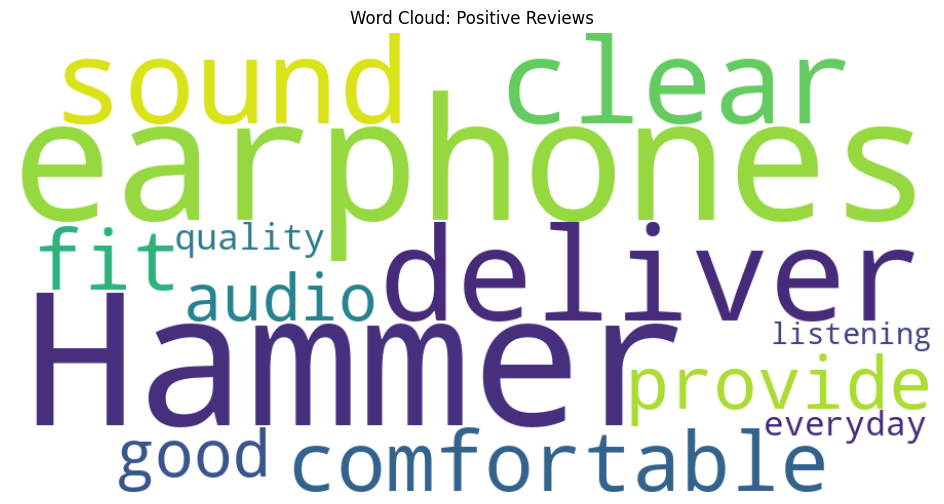

In [22]:
reviews = [
    "The Hammer earphones deliver clear sound, have a comfortable fit, and provide good audio quality for everyday listening.",
    "The Hammer earphones have poor sound quality and stopped working after two days. Very disappointing.",
    "The Hammer earphones arrived today. The package contains the earphones, charging cable, and user manual."
]

sia = SentimentIntensityAnalyzer()
positive_reviews = []
sentiment_results = []

for i, review in enumerate(reviews, start=1):
    scores = sia.polarity_scores(review)
    compound = scores["compound"]
    if compound >= 0.05:
        label = "Positive"
        positive_reviews.append(review)
    elif compound <= -0.05:
        label = "Negative"
    else:
        label = "Neutral"
    sentiment_results.append((i, review, scores, label))
    print(f"Review {i}: {label}")
    print(f"  VADER scores: {scores}")
    print(f"  Review: {review}\n")


positive_text = " ".join(positive_reviews)
if positive_text.strip():
    cloud = WordCloud(width=900, height=450, background_color="white",
                      collocations=False).generate(positive_text)
    plt.figure(figsize=(12, 6))
    plt.imshow(cloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud: Positive Reviews")
    plt.show()
else:
    print("No positive reviews were classified, so no word cloud was generated.")

---
## Question 6 — LSTM Next-Word Text Generation


In [23]:
corpus = """
Chess is a strategic board game played between two opponents on a square board.
Each player begins with sixteen pieces, including a king, queen, rooks, bishops, knights, and pawns.
The objective of chess is to checkmate the opponent's king by placing it under an unavoidable attack.
Players move their pieces according to specific rules and develop strategies to control the board.
The opening phase focuses on developing pieces, controlling the center, and protecting the king.
During the middlegame, players launch attacks, defend their pieces, and search for tactical opportunities.
The endgame begins when fewer pieces remain, making pawn promotion and king activity increasingly important.
Improving at chess requires patience, careful calculation, regular practice, and learning from mistakes.
""".strip()


tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts([corpus])
total_words = len(tokenizer.word_index) + 1
print("Vocabulary size:", total_words)


input_sequences = []
for line in corpus.split("\n"):
    line = line.strip()
    if not line:
        continue
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(2, len(token_list) + 1):
        input_sequences.append(token_list[:i])

if not input_sequences:
    raise ValueError("The corpus did not produce any training sequences.")

max_sequence_len = max(len(seq) for seq in input_sequences)
padded_sequences = pad_sequences(input_sequences, maxlen=max_sequence_len, padding="pre")
X = padded_sequences[:, :-1]
y = to_categorical(padded_sequences[:, -1], num_classes=total_words)

model = Sequential([
    Embedding(input_dim=total_words, output_dim=32, input_length=max_sequence_len - 1),
    LSTM(64),
    Dense(total_words, activation="softmax")
])
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()


history = model.fit(X, y, epochs=100, verbose=0)
print("Training complete.")
print(f"Final training accuracy: {history.history['accuracy'][-1]:.3f}")

Vocabulary size: 87


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Training complete.
Final training accuracy: 0.771


In [24]:
def generate_text(seed_text, next_words, model, max_sequence_len):
    generated = seed_text.strip()
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([generated])[0]
        token_list = pad_sequences(
            [token_list], maxlen=max_sequence_len - 1, padding="pre"
        )
        predictions = model.predict(token_list, verbose=0)[0]


        predicted_index = int(np.argmax(predictions))
        if predicted_index == 0:
            break
        output_word = tokenizer.index_word.get(predicted_index)
        if not output_word or output_word == "<OOV>":
            break
        generated += " " + output_word
    return generated

print(generate_text("chess is", 20, model, max_sequence_len))
print()
print(generate_text("the opening phase", 20, model, max_sequence_len))

chess is is is to to calculation and and learning learning from it an attack attack attack attack attack attack attack attack

the opening phase pieces pieces pieces pieces pieces center and and king king increasingly increasingly important under an an attack attack attack attack
